In [1]:
import torch, os
import segmentation_models_pytorch as smp
import numpy as np
import nibabel as nib
import functools
from torchvision.tv_tensors import Mask
from torchvision.transforms import v2
import matplotlib.pyplot as plt


dataset_dir = "Totalsegmentator_dataset_small_v201"
LUNG_LOBES = [
    "lung_upper_lobe_left", "lung_upper_lobe_right", "lung_middle_lobe_right",
    "lung_lower_lobe_left", "lung_lower_lobe_right",
]
HU_MIN, HU_MAX = -1000, 200
IMG_SIZE = 256
SLICE_MARGIN = 10
RANDOM_SEED = 0
np_rng = lambda: np.random.default_rng(RANDOM_SEED)

/home/jakub/micromamba/envs/fish-segmentation/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
def count_lung_voxels(case):
    n = sum(
        np.count_nonzero(
            np.asarray(
                nib.load(
                    os.path.join(dataset_dir, case, "segmentations", f"{lobe}.nii.gz")
                ).dataobj
            )
        )
        for lobe in LUNG_LOBES
    )
    return n


def calcualte_indexes(min_lung_voxels=1):
    idx_arr = [(x, count_lung_voxels(x)) for x in sorted(filter(lambda x: "." not in x, os.listdir(dataset_dir)))]
    idx_arr = [(x, c) for x, c in idx_arr if c > 0]
    np_rng().shuffle(idx_arr)
    num_samples = len(idx_arr)

    ratios = [0.60, 0.20, 0.20]
    proportions = np.array(ratios) / np.sum(ratios)
    cuts = np.round(np.cumsum(proportions)[:-1] * num_samples).astype(int)

    counts = dict(idx_arr)
    names, _ = zip(*idx_arr)
    splits = np.split(np.array(names), cuts.tolist())
    return [[x for x in s if counts[x] >= min_lung_voxels] for s in splits]

In [3]:
def normalize_hu(x):
    return (np.clip(x, HU_MIN, HU_MAX) - HU_MIN) / (HU_MAX - HU_MIN)

def calculate_box(y):
    xs = np.flatnonzero(y.any((1,2)))
    ys = np.flatnonzero(y.any((0,2)))
    zs = np.flatnonzero(y.any((0,1)))
    return (xs[0], xs[-1]), (ys[0], ys[-1]), (zs[0], zs[-1])

def resize(x, mode):
    x = torch.from_numpy(np.ascontiguousarray(x, dtype=np.float32))
    return torch.nn.functional.interpolate(x[None, None], size=(IMG_SIZE, IMG_SIZE), mode=mode)[0]
    
def crop(x, y, box, rng, jitter=True):
    (x0, x1), (y0, y1) = box
    m = rng.uniform(0.1, 0.3) if jitter else 0.2
    side = round((max(x1 - x0, y1 - y0) + 1) * (1 + 2 * m))
    center = np.array([x0 + x1, y0 + y1]) / 2 + side
    x, y = np.pad(x, side), np.pad(y, side)
    if jitter:
        center = center + rng.uniform(-0.1, 0.1, 2) * side
    
    x0_t = int(center[0]-side/2)
    x1_t = int(center[0]+side/2)
    y0_t = int(center[1]-side/2)
    y1_t = int(center[1]+side/2)
    x, y = x[x0_t:x1_t, y0_t:y1_t], y[x0_t:x1_t, y0_t:y1_t]
    return resize(x, "bilinear"), resize(y, "nearest")

def augment(x, y, rng):
    return x, y

@functools.lru_cache(maxsize=10)
def load_lung(path):
    p_main = os.path.join(path, "ct.nii.gz")
    scan = nib.as_closest_canonical(nib.load(p_main)).get_fdata(dtype=np.float32)

    mask = np.zeros_like(scan, dtype=np.bool)
    for lobe in LUNG_LOBES:
        p_lobe = os.path.join(path, "segmentations", f"{lobe}.nii.gz")
        mask |= np.asarray(nib.as_closest_canonical(nib.load(p_lobe)).dataobj) > 0

    return normalize_hu(scan), mask


class LungDataset(torch.utils.data.Dataset):
    def __init__(self, id_list, dataset_dir, train=False) -> None:
        super().__init__()
        self._rng = np.random.default_rng(RANDOM_SEED)
        self._volumes = [load_lung(os.path.join(dataset_dir, case)) for case in id_list]
        self._slices, self._boxes = [], []
        for i, (_, mask) in enumerate(self._volumes):
            x,y,z = calculate_box(mask)
            self._boxes.append((x,y))
            for k in range(z[0], z[1] + 1):
                self._slices.append((i, k))

        self._train = train
        self._augment = v2.Compose([
            v2.RandomHorizontalFlip(),
            v2.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1), fill=0),
        ])
        self._apply_noise = v2.GaussianNoise(sigma=0.02)

    def __len__(self) -> int:
        return len(self._slices)

    def __getitem__(self, idx):
        i, k = self._slices[idx]
        scan, mask = self._volumes[i]
        x, y = crop(scan[:, :, k], mask[:, :, k], self._boxes[i], self._rng, jitter=self._train)
        
        if self._train:
            x, y = self._augment(x, Mask(y))
            x = self._apply_noise(x)

        return x, y

In [4]:
import torch.nn.functional as F
import gc

DEVICE = "cuda"
BATCH_SIZE = 16
LR = 1e-4
EPOCHS = 15
DICE_TARGET = 0.95
MIN_LUNG_VOXELS = 50000
MIN_EPOCHS = 3

_, test_idx, val_idx = calcualte_indexes(MIN_LUNG_VOXELS)
test_dataset = LungDataset(test_idx, dataset_dir)
val_dataset = LungDataset(val_idx, dataset_dir)

for min_voxels in [1, MIN_LUNG_VOXELS]:

    # prevent oom
    for name in ["train_dataset", "train_loader"]:
        globals().pop(name, None)
        load_lung.cache_clear()
    gc.collect()
    torch.cuda.empty_cache()

    train_idx, _, _ = calcualte_indexes(min_voxels)
    train_dataset = LungDataset(train_idx, dataset_dir, train=True)
    CKPT = f"checkpoints/lung_unet_2d_best-minvox{min_voxels}.pt"

    torch.manual_seed(RANDOM_SEED)
    model = smp.Unet("resnet34", encoder_weights="imagenet", in_channels=1, classes=1).to(
        DEVICE
    )
    opt = torch.optim.AdamW(model.parameters(), lr=LR)
    train_loader = torch.utils.data.DataLoader(
        train_dataset,
        BATCH_SIZE,
        shuffle=True,
        generator=torch.Generator().manual_seed(RANDOM_SEED),
    )
    val_loader = torch.utils.data.DataLoader(val_dataset, BATCH_SIZE)


    def loss_fn(logits, y):
        p = torch.sigmoid(logits)
        inter = (p * y).sum((1, 2, 3))
        dice = (2 * inter + 1) / (p.sum((1, 2, 3)) + y.sum((1, 2, 3)) + 1)
        return F.binary_cross_entropy_with_logits(logits, y) + 1 - dice.mean()


    @torch.no_grad()
    def val_dice(model, loader):
        model.eval()
        inter = total = 0
        for x, y in loader:
            p = model(x.to(DEVICE)) > 0
            y = y.to(DEVICE) > 0.5
            inter += (p & y).sum().item()
            total += p.sum().item() + y.sum().item()
        return 2 * inter / total


    os.makedirs(os.path.dirname(CKPT), exist_ok=True)
    best, best_epoch = -1.0, 0
    for epoch in range(1, EPOCHS + 1):
        model.train()
        running = 0.0
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            loss = loss_fn(model(x), y)
            opt.zero_grad()
            loss.backward()
            opt.step()
            running += loss.item() * len(x)
        dice = val_dice(model, val_loader)
        print(
            f"epoch {epoch:2d}  train loss {running / len(train_dataset):.4f}"
            f"  val Dice {dice:.4f}"
        )
        if dice > best:
            best, best_epoch = dice, epoch
            torch.save(
                {
                    "model": model.state_dict(),
                    "epoch": epoch,
                    "val_dice": dice,
                    "preprocessing": {
                        "hu_window": [HU_MIN, HU_MAX],
                        "img_size": IMG_SIZE,
                        "in_channels": 1,
                        "margin": [0.1, 0.3],
                        "eval_margin": 0.2,
                        "encoder": "resnet34",
                        "weights": "imagenet",
                    },
                },
                CKPT,
            )
        if epoch >= MIN_EPOCHS and dice >= DICE_TARGET:
            break
    print(f"best val Dice {best:.4f} at epoch {best_epoch} -> {CKPT}")

MIOpen(HIP): Warning [ParseAndLoadDb] File is unreadable: "/home/jakub/micromamba/envs/fish-segmentation/lib/python3.14/site-packages/_rocm_sdk_libraries/share/miopen/db/gfx1201_32.HIP.fdb.txt"


epoch  1  train loss 0.7102  val Dice 0.9763
epoch  2  train loss 0.2398  val Dice 0.9788
epoch  3  train loss 0.1149  val Dice 0.9793
best val Dice 0.9793 at epoch 3 -> checkpoints/lung_unet_2d_best-minvox1.pt
epoch  1  train loss 0.7423  val Dice 0.9770
epoch  2  train loss 0.2815  val Dice 0.9815
epoch  3  train loss 0.1248  val Dice 0.9820
best val Dice 0.9820 at epoch 3 -> checkpoints/lung_unet_2d_best-minvox50000.pt


checkpoints/lung_unet_2d_best-minvox1.pt  val Dice 0.9793  epoch 3
checkpoints/lung_unet_2d_best-minvox50000.pt  val Dice 0.9820  epoch 3
using checkpoints/lung_unet_2d_best-minvox50000.pt
per-slice Dice p1/p5/p25/p50: [0.44183018 0.81816119 0.9641546  0.98412991]


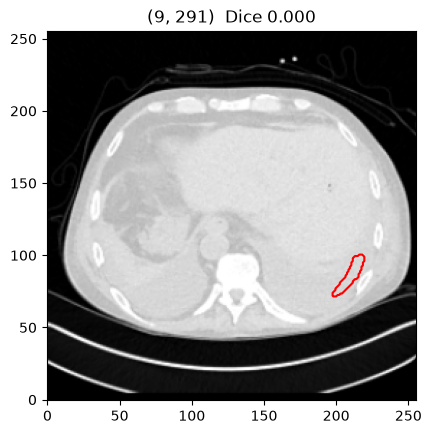

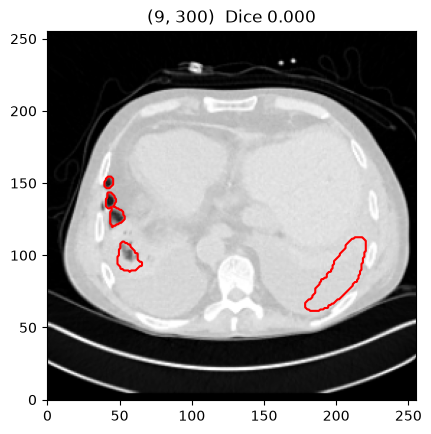

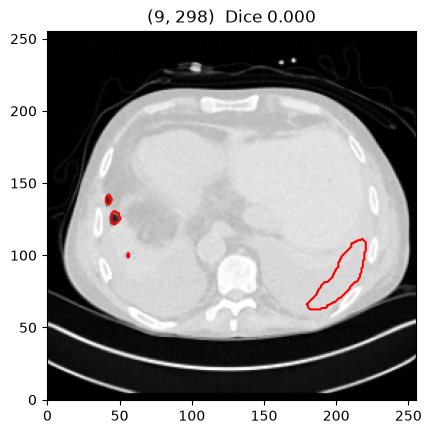

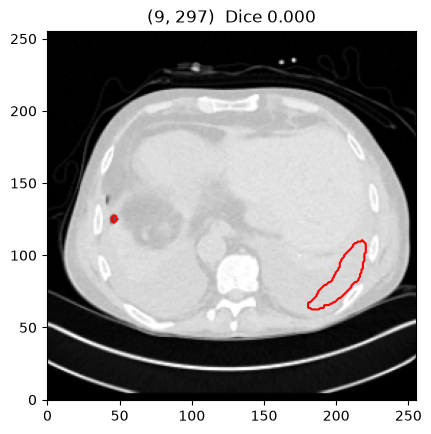

In [5]:
@torch.no_grad()
def slice_dice(model, ds):
    model.eval()
    out = []
    for x, y in torch.utils.data.DataLoader(ds, 64):
        p = model(x.to(DEVICE)) > 0
        y = y.to(DEVICE) > 0.5
        inter = (p & y).sum((1, 2, 3))
        tot = p.sum((1, 2, 3)) + y.sum((1, 2, 3))
        out.append((2 * inter / tot.clamp(min=1)).cpu())
    return torch.cat(out)


import glob

checkpoints = {
    p: torch.load(p, map_location="cpu", weights_only=False)
    for p in glob.glob("checkpoints/lung_unet_2d_best-minvox*.pt")
}
for p, ck in checkpoints.items():
    print(f"{p}  val Dice {ck['val_dice']:.4f}  epoch {ck['epoch']}")

CKPT = max(checkpoints, key=lambda p: checkpoints[p]["val_dice"])
model.load_state_dict(checkpoints[CKPT]["model"])
model.eval()
print("using", CKPT)

d = slice_dice(model, test_dataset)
print("per-slice Dice p1/p5/p25/p50:", np.percentile(d, [1, 5, 25, 50]))
with torch.no_grad():
    for idx in d.argsort()[:4].tolist():
        x, y = test_dataset[idx]
        p = (model(x[None].to(DEVICE)) > 0)[0, 0].float().cpu()
        plt.imshow(x[0].T, cmap="gray", origin="lower")
        plt.contour(y[0].T, levels=[0.5], colors="r")
        plt.contour(p.T, levels=[0.5], colors="c")
        plt.title(f"{test_dataset._slices[idx]}  Dice {d[idx]:.3f}")
        plt.show()

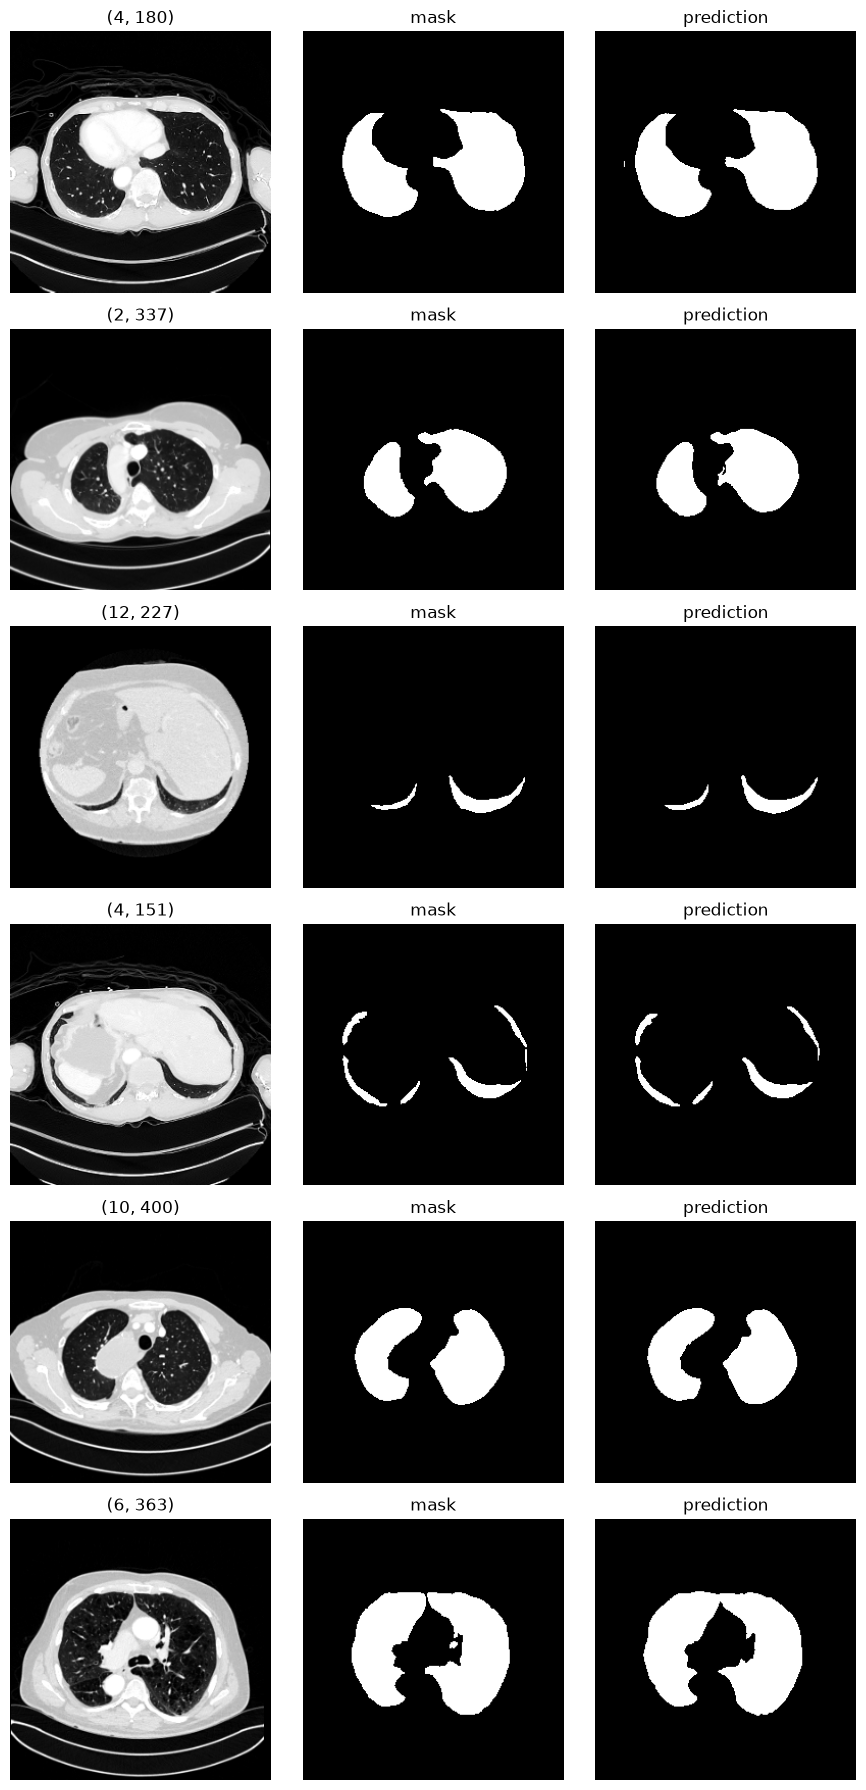

In [6]:
N = 6
model.load_state_dict(
    torch.load(CKPT, map_location=DEVICE, weights_only=False)["model"]
)
model.eval()

indices = np.random.choice(len(test_dataset), N, replace=False)
fig, axes = plt.subplots(N, 3, figsize=(9, 3 * N))

for row, idx in zip(axes, indices):
    x, y = test_dataset[idx]
    slice_info = str(test_dataset._slices[idx])

    with torch.no_grad():
        pred = (model(x.unsqueeze(0).to(DEVICE)) > 0)[0, 0].cpu().float()

    images = [x[0], y[0], pred]
    titles = [slice_info, "mask", "prediction"]

    for ax, img, title in zip(row, images, titles):
        ax.imshow(img.T, cmap="gray", origin="lower")
        ax.set_title(title)
        ax.axis("off")

fig.tight_layout()
plt.show()

In [7]:
FISH = {
    "tuna": ("DD2210_Bluefin_Tuna", "skan_3_DD2210_Bluefin_Tuna.nii.gz", (-1000, 200)),
    "cod": ("Gadus_Morhua", "Gadus_morhua.nii.gz", (3815, 20800)),
    "oreo": ("Oreo_fish", "oreo_density.nii.gz", (1, 1210)),
}


def load_fish(name):
    d, f, (lo, hi) = FISH[name]
    scan = nib.as_closest_canonical(nib.load(os.path.join("..", "data", "raw", d, f)))
    mask = nib.as_closest_canonical(
        nib.load(
            os.path.join("..", "data", "reference_masks", d, "Series_3_segmentation.nii.gz")
            if d == "DD2210_Bluefin_Tuna"
            else os.path.join("..", "data", "reference_masks", d, "Segmentation.nii.gz")
        )
    )
    assert np.allclose(scan.affine, mask.affine, atol=1e-3), name
    x = (np.clip(scan.get_fdata(dtype=np.float32), lo, hi) - lo) / (hi - lo)
    return x, np.asarray(mask.dataobj) > 0, scan.header.get_zooms()

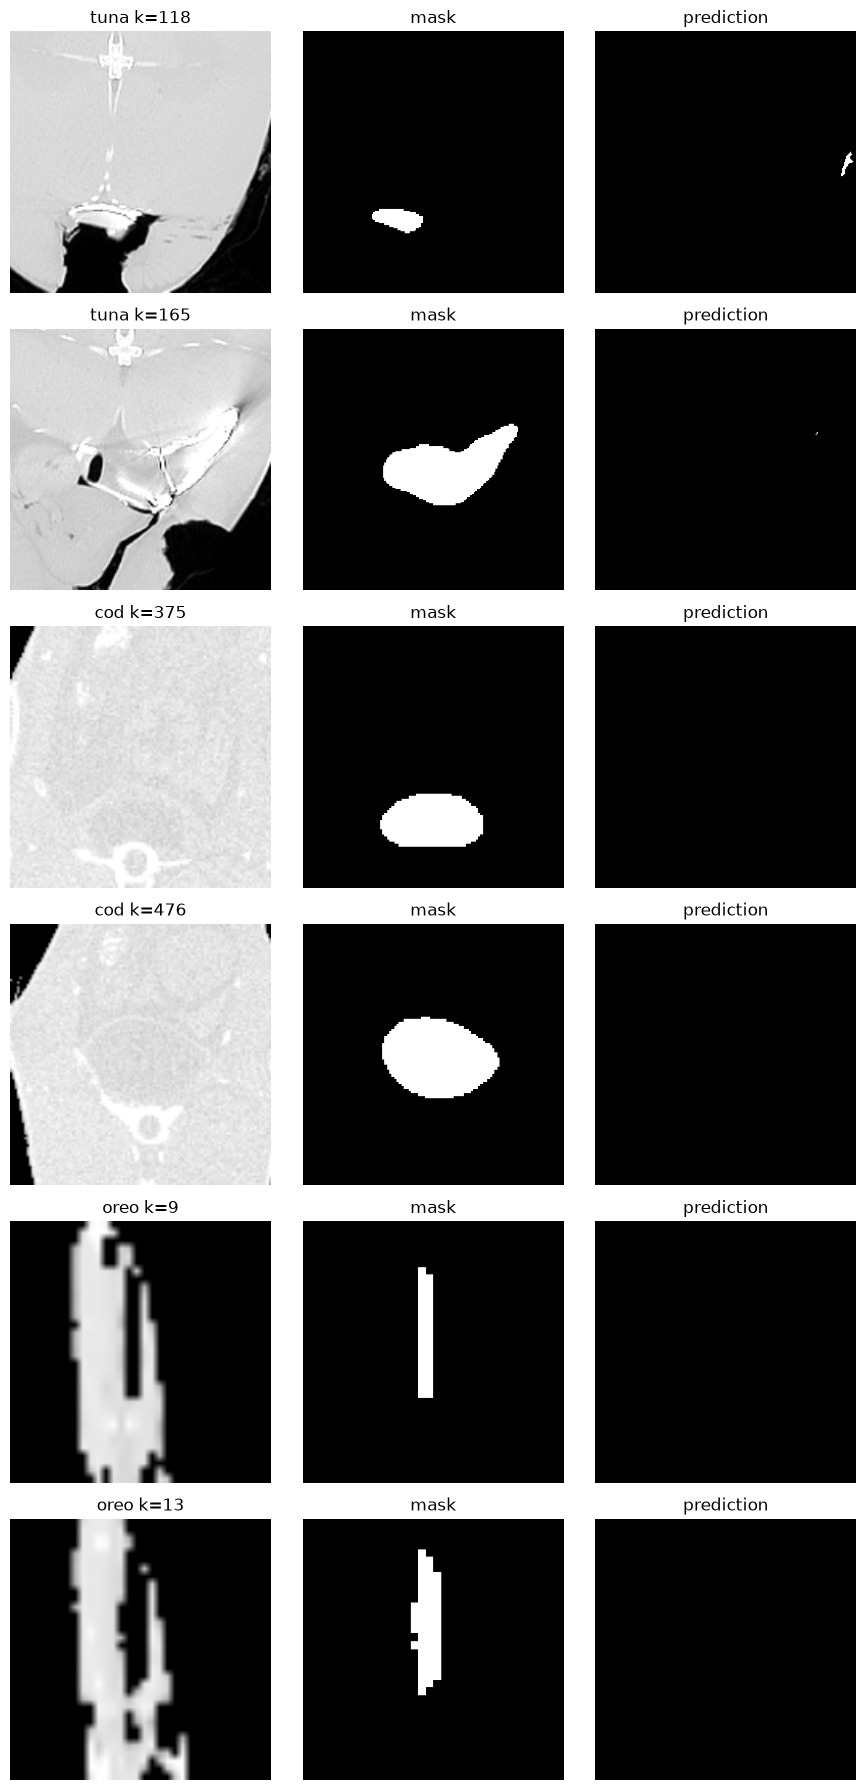

In [8]:
N = 2
fig, axes = plt.subplots(N * len(FISH), 3, figsize=(9, 3 * N * len(FISH)))
rows = iter(axes)

for name in FISH:
    scan, mask, _ = load_fish(name)
    box_x, box_y, _ = calculate_box(mask)
    ks = np.random.choice(np.flatnonzero(mask.any((0, 1))), N, replace=False)
    for k in sorted(ks):
        x, y = crop(scan[:, :, k], mask[:, :, k], (box_x, box_y), None,
                    jitter=False)
        with torch.no_grad():
            pred = (model(x.unsqueeze(0).to(DEVICE)) > 0)[0, 0].cpu().float()

        images = [x[0], y[0], pred]
        titles = [f"{name} k={k}", "mask", "prediction"]
        for ax, img, title in zip(next(rows), images, titles):
            ax.imshow(img.T, cmap="gray", origin="lower")
            ax.set_title(title)
            ax.axis("off")

fig.tight_layout()
plt.show()

fold 0: val z [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
  epoch   0  val Dice 0.1034 (lung only)
  epoch   1  train loss 1.1245  val Dice 0.4352
fold 1: val z [13, 14, 15, 16, 17, 18, 19, 27, 28, 29, 30, 31]
  epoch   0  val Dice 0.0000 (lung only)
  epoch   1  train loss 1.4125  val Dice 0.5873
fold 2: val z [20, 21, 22, 23, 24, 25, 26, 32, 33, 34, 35, 36]
  epoch   0  val Dice 0.0000 (lung only)
  epoch   1  train loss 1.2611  val Dice 0.4220
val Dice per fold [0.2364 0.4352 0.0016 0.5873 0.0125 0.422 ]  mean 0.2825 +- 0.2197


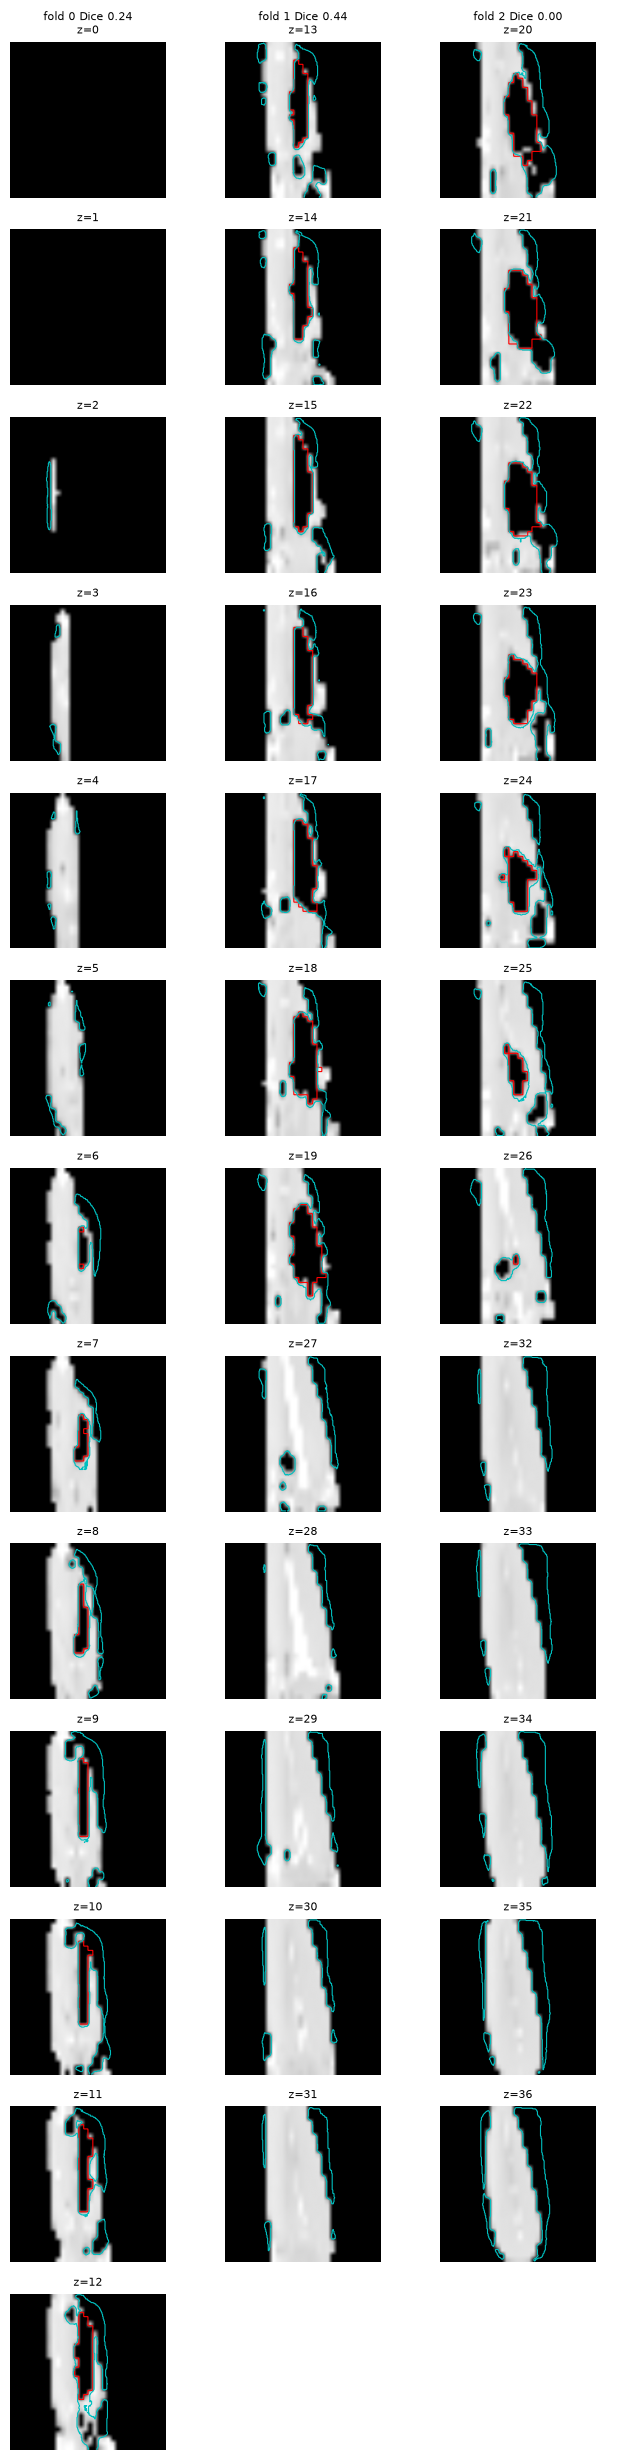

In [9]:
N_FOLDS = 3
FT_EPOCHS = 1

scan, mask, _ = load_fish("oreo")
box_x, box_y, (z0, z1) = calculate_box(mask)
folds = [f.tolist() for f in np.array_split(np.arange(z0, z1 + 1), N_FOLDS)]
empty = list(range(max(z0 - SLICE_MARGIN, 0), z0)) + list(
    range(z1 + 1, min(z1 + SLICE_MARGIN, mask.shape[2] - 1) + 1)
)

for f, chunk in zip(folds, np.array_split(empty, N_FOLDS)):
    f += chunk.tolist()
    f.sort()


class FishDataset(LungDataset):
    def __init__(self, scan, mask, ks, train=False):
        super().__init__([], dataset_dir, train=train)
        box_x, box_y, _ = calculate_box(mask)
        self._volumes = [(scan, mask)]
        self._boxes = [(box_x, box_y)]
        self._slices = [(0, k) for k in ks]


fold_dice, fold_preds = [], []
for fold_n in range(N_FOLDS):
    train_ks = sorted(k for j, f in enumerate(folds) if j != fold_n for k in f)
    train_ds = FishDataset(scan, mask, train_ks, train=True)
    val_ds = FishDataset(scan, mask, folds[fold_n])

    torch.manual_seed(RANDOM_SEED)
    model = smp.Unet("resnet34", encoder_weights=None, in_channels=1, classes=1)
    model.load_state_dict(checkpoints[CKPT]["model"])
    model.to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=LR)
    train_loader = torch.utils.data.DataLoader(
        train_ds,
        BATCH_SIZE,
        shuffle=True,
        generator=torch.Generator().manual_seed(RANDOM_SEED),
    )
    val_loader = torch.utils.data.DataLoader(val_ds, BATCH_SIZE)

    print(f"fold {fold_n}: val z {folds[fold_n]}")
    print(f"  epoch   0  val Dice {val_dice(model, val_loader):.4f} (lung only)")
    for epoch in range(1, FT_EPOCHS + 1):
        model.train()
        running = 0.0
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            loss = loss_fn(model(x), y)
            opt.zero_grad()
            loss.backward()
            opt.step()
            running += loss.item() * len(x)

            fold_dice.append(val_dice(model, val_loader))
    print(f"  epoch {FT_EPOCHS:3d}  train loss {running / len(train_ds):.4f}"
          f"  val Dice {fold_dice[-1]:.4f}")

    model.eval()
    with torch.no_grad():
        xs, ys = map(torch.stack, zip(*[val_ds[i] for i in range(len(val_ds))]))
        ps = (model(xs.to(DEVICE)) > 0).cpu()
    fold_preds.append((xs, ys, ps))

print(f"val Dice per fold {np.round(fold_dice, 4)}"
      f"  mean {np.mean(fold_dice):.4f} +- {np.std(fold_dice):.4f}")

rows = max(len(f) for f in folds)
fig, axes = plt.subplots(rows, N_FOLDS, figsize=(2.2 * N_FOLDS, 1.9 * rows))
for fold_n, (col, (xs, ys, ps)) in enumerate(zip(axes.T, fold_preds)):
    for ax in col:
        ax.axis("off")
    for ax, k, x, y, p in zip(col, folds[fold_n], xs, ys, ps):
        ax.imshow(x[0].T, cmap="gray", origin="lower", vmin=0, vmax=1)
        if y.any():
            ax.contour(y[0].T, levels=[0.5], colors="r", linewidths=0.8)
        if p.any():
            ax.contour(p[0].T.float(), levels=[0.5], colors="c", linewidths=0.8)
        ax.set_title(f"z={k}", fontsize=8)
    col[0].set_title(f"fold {fold_n} Dice {fold_dice[fold_n]:.2f}\nz={folds[fold_n][0]}",
                     fontsize=8)

fig.tight_layout()
plt.show()

In [10]:
N_FOLDS = 3
FT_EPOCHS = 100
EVAL_INTERVAL = 5


def fish_folds(mask):
    _, _, (z0, z1) = calculate_box(mask)
    folds = [f.tolist() for f in np.array_split(np.arange(z0, z1 + 1), N_FOLDS)]
    empty = list(range(max(z0 - SLICE_MARGIN, 0), z0)) + list(
        range(z1 + 1, min(z1 + SLICE_MARGIN, mask.shape[2] - 1) + 1)
    )
    for f, chunk in zip(folds, np.array_split(empty, N_FOLDS)):
        f += chunk.tolist()
        f.sort()
    return folds


class FishDataset(LungDataset):
    def __init__(self, volumes, train=False):
        super().__init__([], dataset_dir, train=train)
        self._volumes = [(scan, mask) for scan, mask, _ in volumes]
        self._boxes = [calculate_box(mask)[:2] for _, mask, _ in volumes]
        self._slices = [(i, k) for i, (_, _, ks) in enumerate(volumes) for k in ks]

    def __getitem__(self, idx):
        x, y = super().__getitem__(idx)
        if self._train:
            # train out rotation dependence
            k = int(self._rng.integers(4))
            x, y = torch.rot90(x, k, (1, 2)), torch.rot90(y, k, (1, 2))
        return x, y


fish = {name: load_fish(name)[:2] for name in FISH}
folds = {name: fish_folds(mask) for name, (_, mask) in fish.items()}

fold_dice = []
fold_loss = []
for fold_n in range(N_FOLDS):
    train_ds = FishDataset(
        [
            (scan, mask, sorted(k for j, f in enumerate(folds[name]) if j != fold_n for k in f))
            for name, (scan, mask) in fish.items()
        ],
        train=True,
    )
    val_loaders = {
        name: torch.utils.data.DataLoader(
            FishDataset([(scan, mask, folds[name][fold_n])]), BATCH_SIZE
        )
        for name, (scan, mask) in fish.items()
    }

    torch.manual_seed(RANDOM_SEED)
    model = smp.Unet("resnet34", encoder_weights=None, in_channels=1, classes=1)
    model.load_state_dict(checkpoints[CKPT]["model"])
    model.to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=LR)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, FT_EPOCHS)
    train_loader = torch.utils.data.DataLoader(
        train_ds,
        BATCH_SIZE,
        shuffle=True,
        generator=torch.Generator().manual_seed(RANDOM_SEED),
    )

    lung = {name: val_dice(model, l) for name, l in val_loaders.items()}
    loss_history = []
    for epoch in range(1, FT_EPOCHS + 1):
        model.train()
        running = 0.0
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            loss = loss_fn(model(x), y)
            opt.zero_grad()
            loss.backward()
            opt.step()
            running += loss.item() * len(x)

        sched.step()

        if epoch % EVAL_INTERVAL == 0:
            loss_history.append({n: val_dice(model, l) for n, l in val_loaders.items()})
            print(f"  epoch {epoch:3d}  loss {running / len(train_ds):.4f}  "
                  + "  ".join(f"{n} {d:.4f}" for n, d in loss_history[-1].items()))
    fold_loss.append(loss_history)

    fold_dice.append({name: val_dice(model, l) for name, l in val_loaders.items()})
    print(f"fold {fold_n}  train loss {running / len(train_ds):.4f}  val Dice "
          + "  ".join(f"{n} {lung[n]:.4f} -> {d:.4f}" for n, d in fold_dice[-1].items()))

for name in FISH:
    d = [fd[name] for fd in fold_dice]
    print(f"{name:5s} val Dice per fold {np.round(d, 4)}"
          f"  mean {np.mean(d):.4f} +- {np.std(d):.4f}")

  epoch   5  loss 0.3807  tuna 0.6730  cod 0.7751  oreo 0.8045
  epoch  10  loss 0.2904  tuna 0.8069  cod 0.7114  oreo 0.8375
  epoch  15  loss 0.2690  tuna 0.7571  cod 0.7605  oreo 0.7197
  epoch  20  loss 0.2495  tuna 0.8079  cod 0.8114  oreo 0.8520
  epoch  25  loss 0.2333  tuna 0.8526  cod 0.8396  oreo 0.8626
  epoch  30  loss 0.2226  tuna 0.8472  cod 0.8615  oreo 0.8203
  epoch  35  loss 0.2160  tuna 0.8169  cod 0.8439  oreo 0.6929
  epoch  40  loss 0.2259  tuna 0.8488  cod 0.6837  oreo 0.5985
  epoch  45  loss 0.2039  tuna 0.8912  cod 0.8723  oreo 0.8815
  epoch  50  loss 0.1916  tuna 0.8543  cod 0.8666  oreo 0.9219
  epoch  55  loss 0.1401  tuna 0.8658  cod 0.8506  oreo 0.8250
  epoch  60  loss 0.1276  tuna 0.8814  cod 0.8742  oreo 0.8556
  epoch  65  loss 0.1328  tuna 0.8446  cod 0.8607  oreo 0.8988
  epoch  70  loss 0.0941  tuna 0.8619  cod 0.8830  oreo 0.8624
  epoch  75  loss 0.0942  tuna 0.8279  cod 0.8580  oreo 0.4955
  epoch  80  loss 0.0855  tuna 0.8188  cod 0.8582  oreo

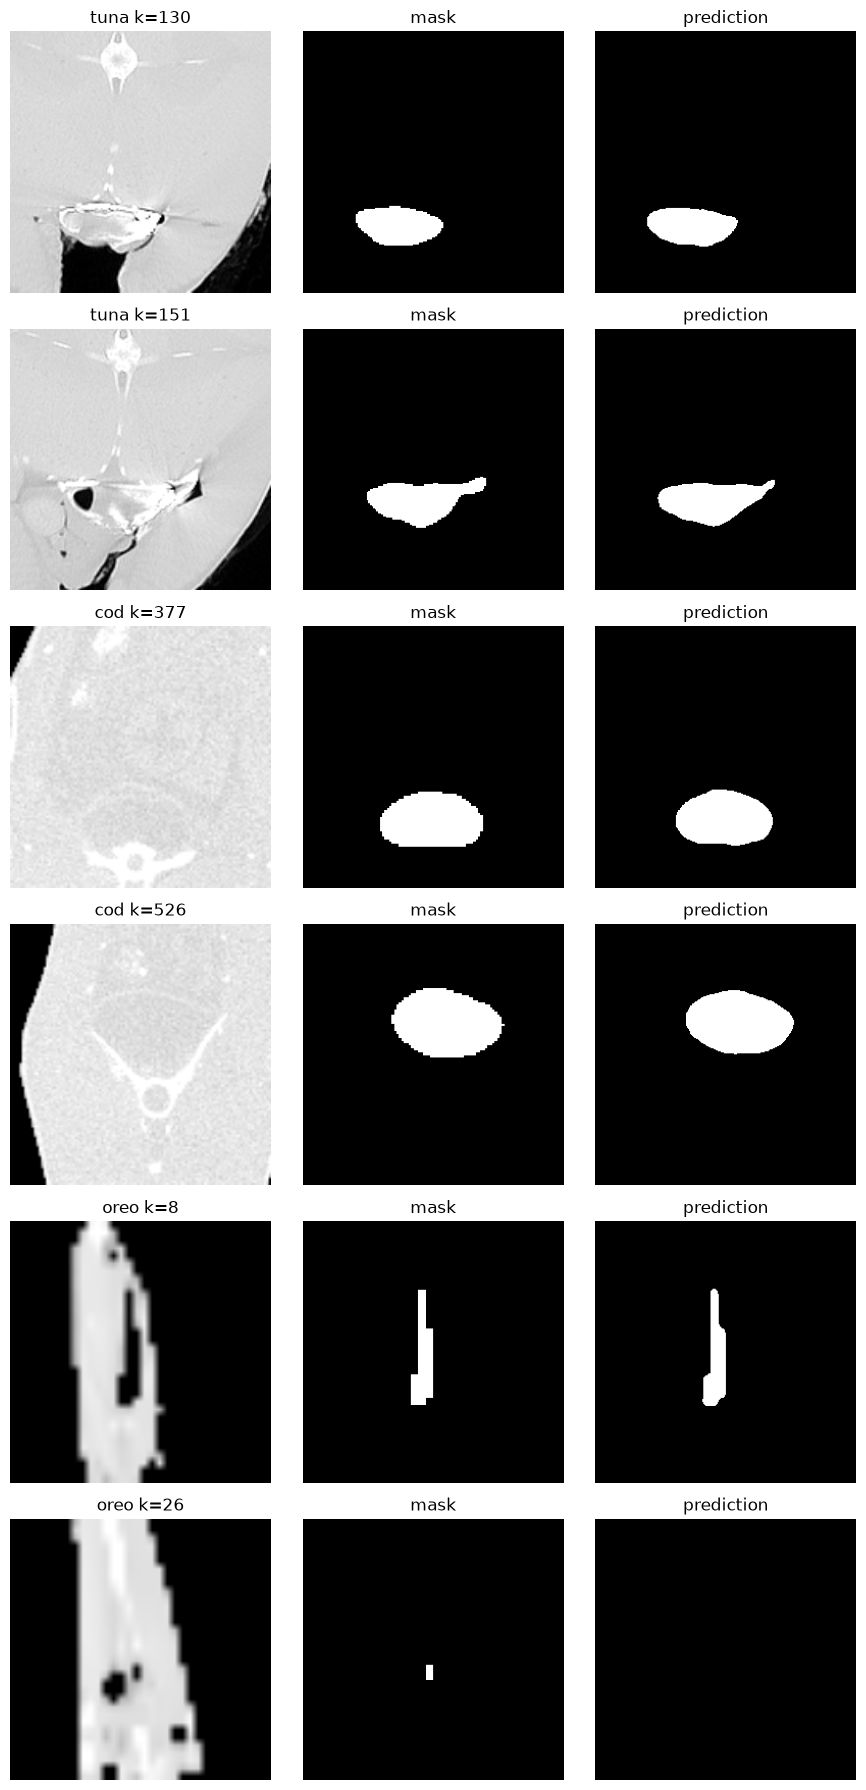

In [11]:
N = 2
fig, axes = plt.subplots(N * len(FISH), 3, figsize=(9, 3 * N * len(FISH)))
rows = iter(axes)

for name in FISH:
    scan, mask, _ = load_fish(name)
    box_x, box_y, _ = calculate_box(mask)
    ks = np.random.choice(np.flatnonzero(mask.any((0, 1))), N, replace=False)
    for k in sorted(ks):
        x, y = crop(scan[:, :, k], mask[:, :, k], (box_x, box_y), None,
                    jitter=False)
        with torch.no_grad():
            pred = (model(x.unsqueeze(0).to(DEVICE)) > 0)[0, 0].cpu().float()

        images = [x[0], y[0], pred]
        titles = [f"{name} k={k}", "mask", "prediction"]
        for ax, img, title in zip(next(rows), images, titles):
            ax.imshow(img.T, cmap="gray", origin="lower")
            ax.set_title(title)
            ax.axis("off")

fig.tight_layout()
plt.show()

In [12]:
train_ds = FishDataset(
    [(scan, mask, sorted(k for f in folds[name] for k in f))
     for name, (scan, mask) in fish.items()],
    train=True,
)

torch.manual_seed(RANDOM_SEED)
model = smp.Unet("resnet34", encoder_weights=None, in_channels=1, classes=1)
model.load_state_dict(checkpoints[CKPT]["model"])
model.to(DEVICE)
opt = torch.optim.AdamW(model.parameters(), lr=LR)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, FT_EPOCHS)
train_loader = torch.utils.data.DataLoader(
    train_ds,
    BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(RANDOM_SEED),
)

for epoch in range(1, FT_EPOCHS + 1):
    model.train()
    loss_sum = 0.0
    for x, y in train_loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        loss = loss_fn(model(x), y)
        opt.zero_grad()
        loss.backward()
        opt.step()
        loss_sum += loss.item() * len(x)
    sched.step()
    if epoch % EVAL_INTERVAL == 0:
        print(f"epoch {epoch:3d}  loss {loss_sum / len(train_ds):.4f}")

torch.save(
    {
        "model": model.state_dict(),
        "epoch": FT_EPOCHS,
        "pretrained_from": CKPT,
        "cv_dice": {n: [fd[n] for fd in fold_dice] for n in FISH},
        "preprocessing": {
            **checkpoints[CKPT]["preprocessing"],
            "windows": {n: FISH[n][2] for n in FISH},
            "eval_margin": 0.2,
        },
    },
    "checkpoints/bladder_unet_2d.pt",
)

epoch   5  loss 0.3607
epoch  10  loss 0.2974
epoch  15  loss 0.2716
epoch  20  loss 0.2502
epoch  25  loss 0.2311
epoch  30  loss 0.1921
epoch  35  loss 0.2548
epoch  40  loss 0.1805
epoch  45  loss 0.1755
epoch  50  loss 0.1300
epoch  55  loss 0.1194
epoch  60  loss 0.1538
epoch  65  loss 0.1322
epoch  70  loss 0.1110
epoch  75  loss 0.1002
epoch  80  loss 0.1104
epoch  85  loss 0.1028
epoch  90  loss 0.1036
epoch  95  loss 0.0980
epoch 100  loss 0.0978
